# Práctica 1 – Predicción de Subscripción a un Producto Bancario
## Aprendizaje Automático · UC3M · 2025-26

**Miembros del equipo:**
- Marcos Truchado (NIA: 100522249)
- Jorge Condado (NIA: 100522327)

---

## Notebook 1

Este notebook cubre la **sección 2 (EDA simplificado)** y la **sección 3 (decisión de evaluación)** de la práctica, y sienta las bases para el preprocesamiento que se aplicará a lo largo del resto del trabajo.

Los notebooks están pensados para ejecutarse desde la **raíz del repositorio**, donde se encuentran `data/bank_13.pkl`, `data/bank_competition.pkl` y `app/streamlit_app.py`. Si las rutas fallan, lo más probable es que el directorio de trabajo no sea el correcto o que falte algún archivo del repositorio.

Para mantener la reproducibilidad, conviene respetar las dependencias indicadas en `requirements.txt`, especialmente la versión de `scikit-learn`, ya que afecta tanto al entrenamiento como a la carga de artefactos como `models/modelo_final.joblib`.

#PARTE 1 - EDA SIMPLIFICADO

## 0- Configuración Inicial

In [1]:
# ── Instalar librerías (solo necesario en Colab) ──────────────────────────────
# !pip install -q pandas numpy matplotlib seaborn scikit-learn

!pip install -q "scikit-learn==1.8.0"

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Semilla reproducibilidad
SEED = 100522249

# Estética general de plots
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 110

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 1- Carga de datos

In [2]:
from pathlib import Path

# Ficheros en la raíz del proyecto (directorio de trabajo del kernel = carpeta del repo)
_ROOT = Path.cwd()
DATA_PATH = _ROOT / 'data/bank_13.pkl'
COMP_PATH = _ROOT / 'data/bank_competition.pkl'

with open(DATA_PATH, 'rb') as f:
    df = pickle.load(f)

with open(COMP_PATH, 'rb') as f:
    df_comp = pickle.load(f)

print(f'Dataset principal  → {df.shape[0]:,} instancias, {df.shape[1]} variables')
print(f'Dataset competición → {df_comp.shape[0]:,} instancias, {df_comp.shape[1]} variables')
df.head(3)

Dataset principal  → 11,000 instancias, 17 variables
Dataset competición → 162 instancias, 16 variables


/tmp/ipykernel_4188/2834216689.py:9: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  df = pickle.load(f)
/tmp/ipykernel_4188/2834216689.py:12: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use th

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes


##2- EDA Simplificado

### 2.1 Dimensiones del dataset

In [3]:
n_rows, n_cols = df.shape
print(f'Número de instancias : {n_rows:,}')
print(f'Número de variables  : {n_cols}  ({n_cols - 1} features + 1 target)')

Número de instancias : 11,000
Número de variables  : 17  (16 features + 1 target)


El análisis exploratorio se organiza de lo general a lo específico: primero se revisa la estructura del dataset, después su calidad y tipología de variables, y finalmente se estudian distribuciones, relaciones y decisiones de preprocesado que condicionarán los modelos posteriores.

Antes de entrar en el detalle de cada variable, conviene fijar dos ideas. Primero, el tamaño muestral es suficientemente amplio como para que las frecuencias observadas sean informativas y no dependan en exceso de fluctuaciones pequeñas. Segundo, como el objetivo es una variable binaria (`deposit`), interesa distinguir desde el principio qué atributos requerirán tratamiento numérico y cuáles necesitarán codificación categórica dentro del pipeline.

### 2.2 Tipos de variables

In [4]:
TARGET = 'deposit'

features = df.drop(columns=[TARGET])

num_cols = features.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = features.select_dtypes(include=['object', 'category']).columns.tolist()

# Resumen tipo
type_df = pd.DataFrame({
    'Variable': df.columns,
    'Dtype'   : df.dtypes.values,
    'Tipo'    : ['TARGET' if c == TARGET
                 else 'Numérica' if c in num_cols
                 else 'Categórica'
                 for c in df.columns],
    'N_únicos': [df[c].nunique() for c in df.columns]
})

print(type_df.to_string(index=False))
print(f'\n→ Numéricas  ({len(num_cols)}): {num_cols}')
print(f'→ Categóricas ({len(cat_cols)}): {cat_cols}')

 Variable  Dtype       Tipo  N_únicos
      age  int64   Numérica        76
      job object Categórica        12
  marital object Categórica         3
education object Categórica         4
  default object Categórica         2
  balance  int64   Numérica      3783
  housing object Categórica         2
     loan object Categórica         2
  contact object Categórica         3
      day  int64   Numérica        31
    month object Categórica        12
 duration  int64   Numérica      1423
 campaign  int64   Numérica        36
    pdays  int64   Numérica       472
 previous  int64   Numérica        34
 poutcome object Categórica         4
  deposit object     TARGET         2

→ Numéricas  (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
→ Categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


### 2.3 Cardinalidad de variables categóricas

> Alta cardinalidad: >10 valores únicos

In [5]:
HIGH_CARD_THRESHOLD = 10

card_df = pd.DataFrame({
    'Variable'    : cat_cols,
    'N_únicos'    : [df[c].nunique() for c in cat_cols],
    'Alta_card.'  : [df[c].nunique() > HIGH_CARD_THRESHOLD for c in cat_cols],
    'Valores'     : [sorted(df[c].dropna().unique().tolist()) for c in cat_cols]
})

print(card_df[['Variable', 'N_únicos', 'Alta_card.']].to_string(index=False))

high_card = card_df[card_df['Alta_card.']]['Variable'].tolist()
if high_card:
    print(f'\n Variables con alta cardinalidad: {high_card}')
else:
    print('\nNinguna variable categórica tiene alta cardinalidad (>10 valores únicos).')

 Variable  N_únicos  Alta_card.
      job        12        True
  marital         3       False
education         4       False
  default         2       False
  housing         2       False
     loan         2       False
  contact         3       False
    month        12        True
 poutcome         4       False

 Variables con alta cardinalidad: ['job', 'month']


### 2.4 Valores faltantes

In [6]:
# En este dataset los NaN pueden estar codificados como None o como la string 'unknown'
# Comprobamos ambas formas
missing_none = df.isnull().sum()

# 'unknown' en categóricas (no es técnicamente NaN, pero puede serlo semánticamente)
unknown_counts = pd.Series({
    c: (df[c] == 'unknown').sum()
    for c in cat_cols
})

missing_df = pd.DataFrame({
    'Variable'        : df.columns,
    'Missing (None)'  : missing_none.values,
    '% Missing'       : (missing_none / len(df) * 100).round(2).values,
})

print('=== Valores faltantes (None/NaN) ===')
print(missing_df[missing_df['Missing (None)'] > 0].to_string(index=False))
if missing_df['Missing (None)'].sum() == 0:
    print('  → Ninguna variable tiene NaN reales.')

print('\n=== Valores "unknown" en categóricas (missing semántico) ===')
uk_df = unknown_counts[unknown_counts > 0]
if len(uk_df):
    print(pd.DataFrame({'Variable': uk_df.index,
                        'N unknown': uk_df.values,
                        '% unknown': (uk_df / len(df) * 100).round(2).values}).to_string(index=False))
else:
    print('  → Ninguna.')

=== Valores faltantes (None/NaN) ===
Variable  Missing (None)  % Missing
 marital             406       3.69

=== Valores "unknown" en categóricas (missing semántico) ===
 Variable  N unknown  % unknown
      job         68       0.62
education        494       4.49
  contact       2309      20.99
 poutcome       8205      74.59


### 2.5 Columnas constantes e identificadores

In [7]:
# Columnas constantes (1 único valor)
const_cols = [c for c in df.columns if df[c].nunique() <= 1]

# Posibles columnas ID: numéricas con todos los valores únicos
id_cols = [c for c in num_cols if df[c].nunique() == len(df)]

print(f'Columnas constantes : {const_cols if const_cols else "Ninguna"}')
print(f'Posibles columnas ID: {id_cols if id_cols else "Ninguna"}')

Columnas constantes : Ninguna
Posibles columnas ID: Ninguna


### 2.6 Tipo de problema y balance de clases

Variable objetivo : deposit
Dtype             : object
Valores únicos    : 2  → Clasificación binaria

Distribución de clases:
Clase    N     %
   no 5780 52.55
  yes 5220 47.45

Ratio de desbalanceo: 1.11
 Dataset prácticamente balanceado.


/tmp/ipykernel_4188/3226115036.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=TARGET, ax=ax, palette='Set2')


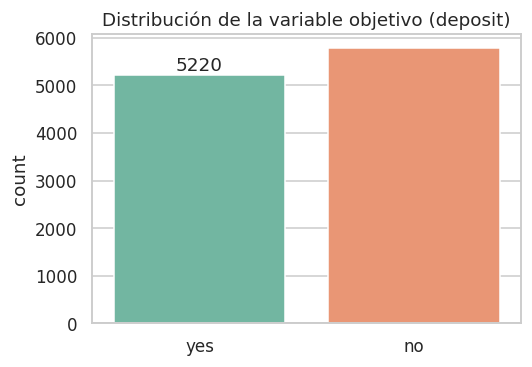

In [8]:
target_dtype   = df[TARGET].dtype
target_nunique = df[TARGET].nunique()

problem_type = 'Clasificación binaria' if target_nunique == 2 else \
               'Clasificación multiclase' if target_nunique < 20 else 'Regresión'

print(f'Variable objetivo : {TARGET}')
print(f'Dtype             : {target_dtype}')
print(f'Valores únicos    : {target_nunique}  → {problem_type}')

vc = df[TARGET].value_counts()
vc_pct = df[TARGET].value_counts(normalize=True) * 100
balance_df = pd.DataFrame({'Clase': vc.index, 'N': vc.values, '%': vc_pct.round(2).values})
print(f'\nDistribución de clases:')
print(balance_df.to_string(index=False))

imbalance_ratio = vc.max() / vc.min()
print(f'\nRatio de desbalanceo: {imbalance_ratio:.2f}')
if imbalance_ratio > 1.5:
    print('  Dataset moderadamente desbalanceado.')
else:
    print(' Dataset prácticamente balanceado.')

# Plot
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=TARGET, ax=ax, palette='Set2')
ax.bar_label(ax.containers[0], fmt='%d')
ax.set_title('Distribución de la variable objetivo (deposit)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

### 2.7 Distribución de variables numéricas

### Lectura de las distribuciones numéricas

Los histogramas permiten comprobar hasta qué punto las clases `deposit = yes` y `deposit = no` se solapan en cada variable. Cuando las distribuciones son muy parecidas, esa variable por sí sola difícilmente separará bien las clases; cuando cambian su forma, dispersión o concentración, puede aportar señal útil al modelo.

En este dataset también se observan asimetrías y colas largas en algunas variables financieras y de interacción. Eso no obliga a transformarlas de inmediato, pero sí justifica usar modelos robustos a relaciones no lineales y acompañar el análisis visual con escalado y validación cruzada.

=== Estadísticos descriptivos (numéricas) ===
            count     mean      std     min     25%    50%      75%      max
age       11000.0    41.25    11.94    18.0   32.00   39.0    49.00     95.0
balance   11000.0  1529.14  3217.40 -6847.0  122.75  549.5  1711.00  81204.0
day       11000.0    15.66     8.42     1.0    8.00   15.0    22.00     31.0
duration  11000.0   372.52   347.52     2.0  138.00  255.0   498.00   3881.0
campaign  11000.0     2.51     2.72     1.0    1.00    2.0     3.00     63.0
pdays     11000.0    51.31   108.78    -1.0   -1.00   -1.0    20.25    854.0
previous  11000.0     0.83     2.28     0.0    0.00    0.0     1.00     58.0


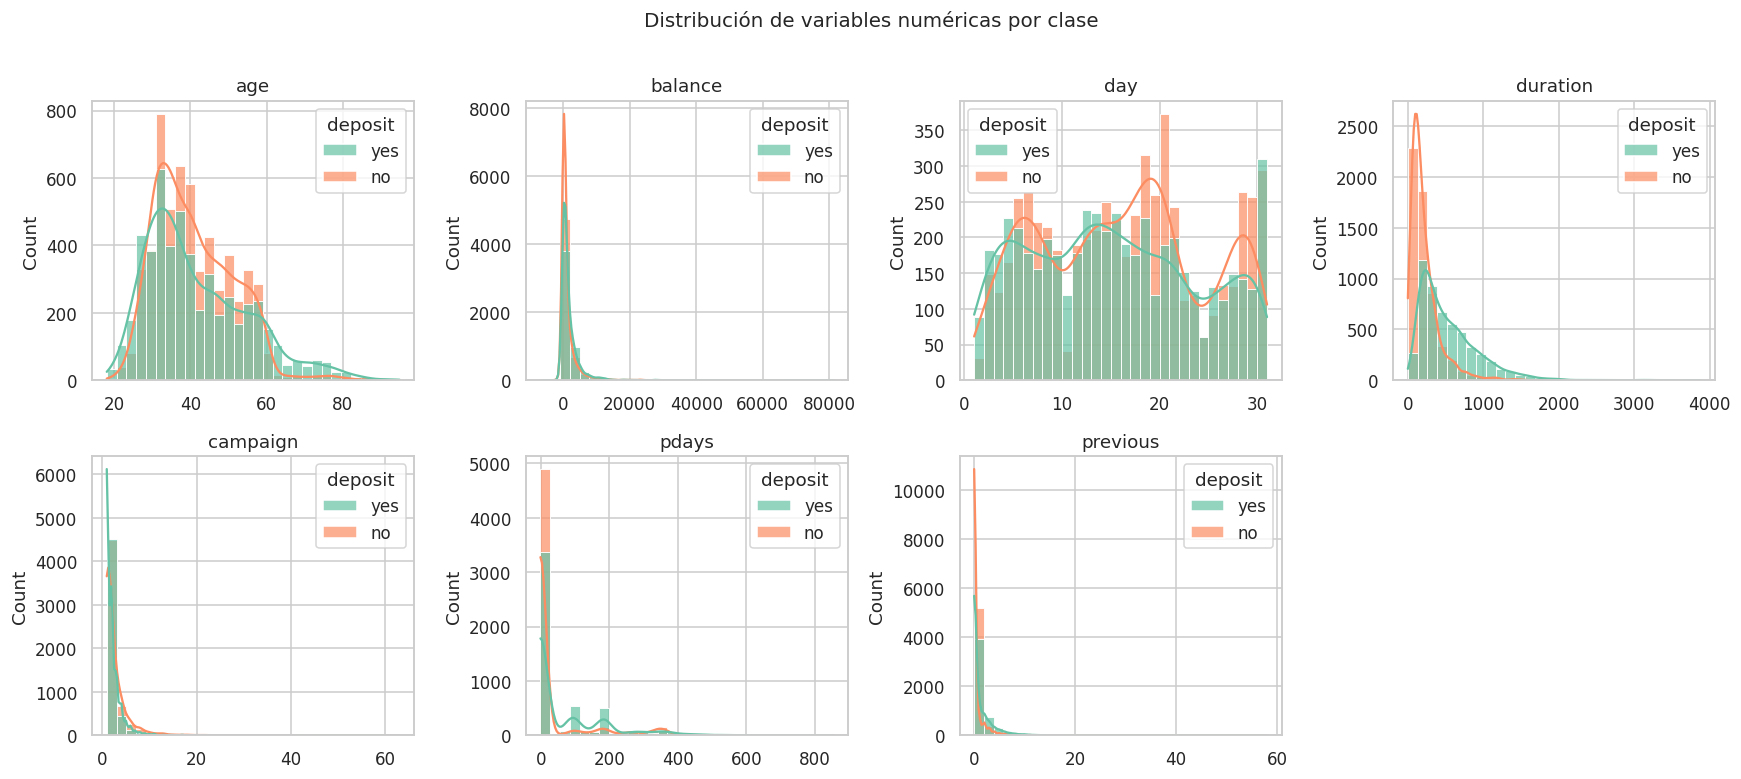

In [9]:
print('=== Estadísticos descriptivos (numéricas) ===')
print(df[num_cols].describe().round(2).T.to_string())

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    if i >= len(axes):
        break
    sns.histplot(data=df, x=col, hue=TARGET, ax=axes[i],
                 kde=True, bins=30, palette='Set2', alpha=0.7)
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# Ocultar ejes sobrantes
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribución de variables numéricas por clase', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 2.8 Distribución de variables categóricas

### Qué aportan las variables categóricas

Estas gráficas permiten comparar no solo la frecuencia de cada categoría, sino también cómo cambia la proporción de la clase objetivo dentro de cada grupo. Ese contraste es especialmente útil para detectar atributos que pueden tener poder predictivo aun cuando su distribución global no parezca llamativa.

En este problema, variables como el historial de campañas previas, el canal de contacto o el mes pueden reflejar contextos comerciales distintos. Por eso, aunque después se codifiquen con `OneHotEncoder`, aquí ya se puede anticipar qué categorías parecen asociarse con tasas de suscripción más altas o más bajas.

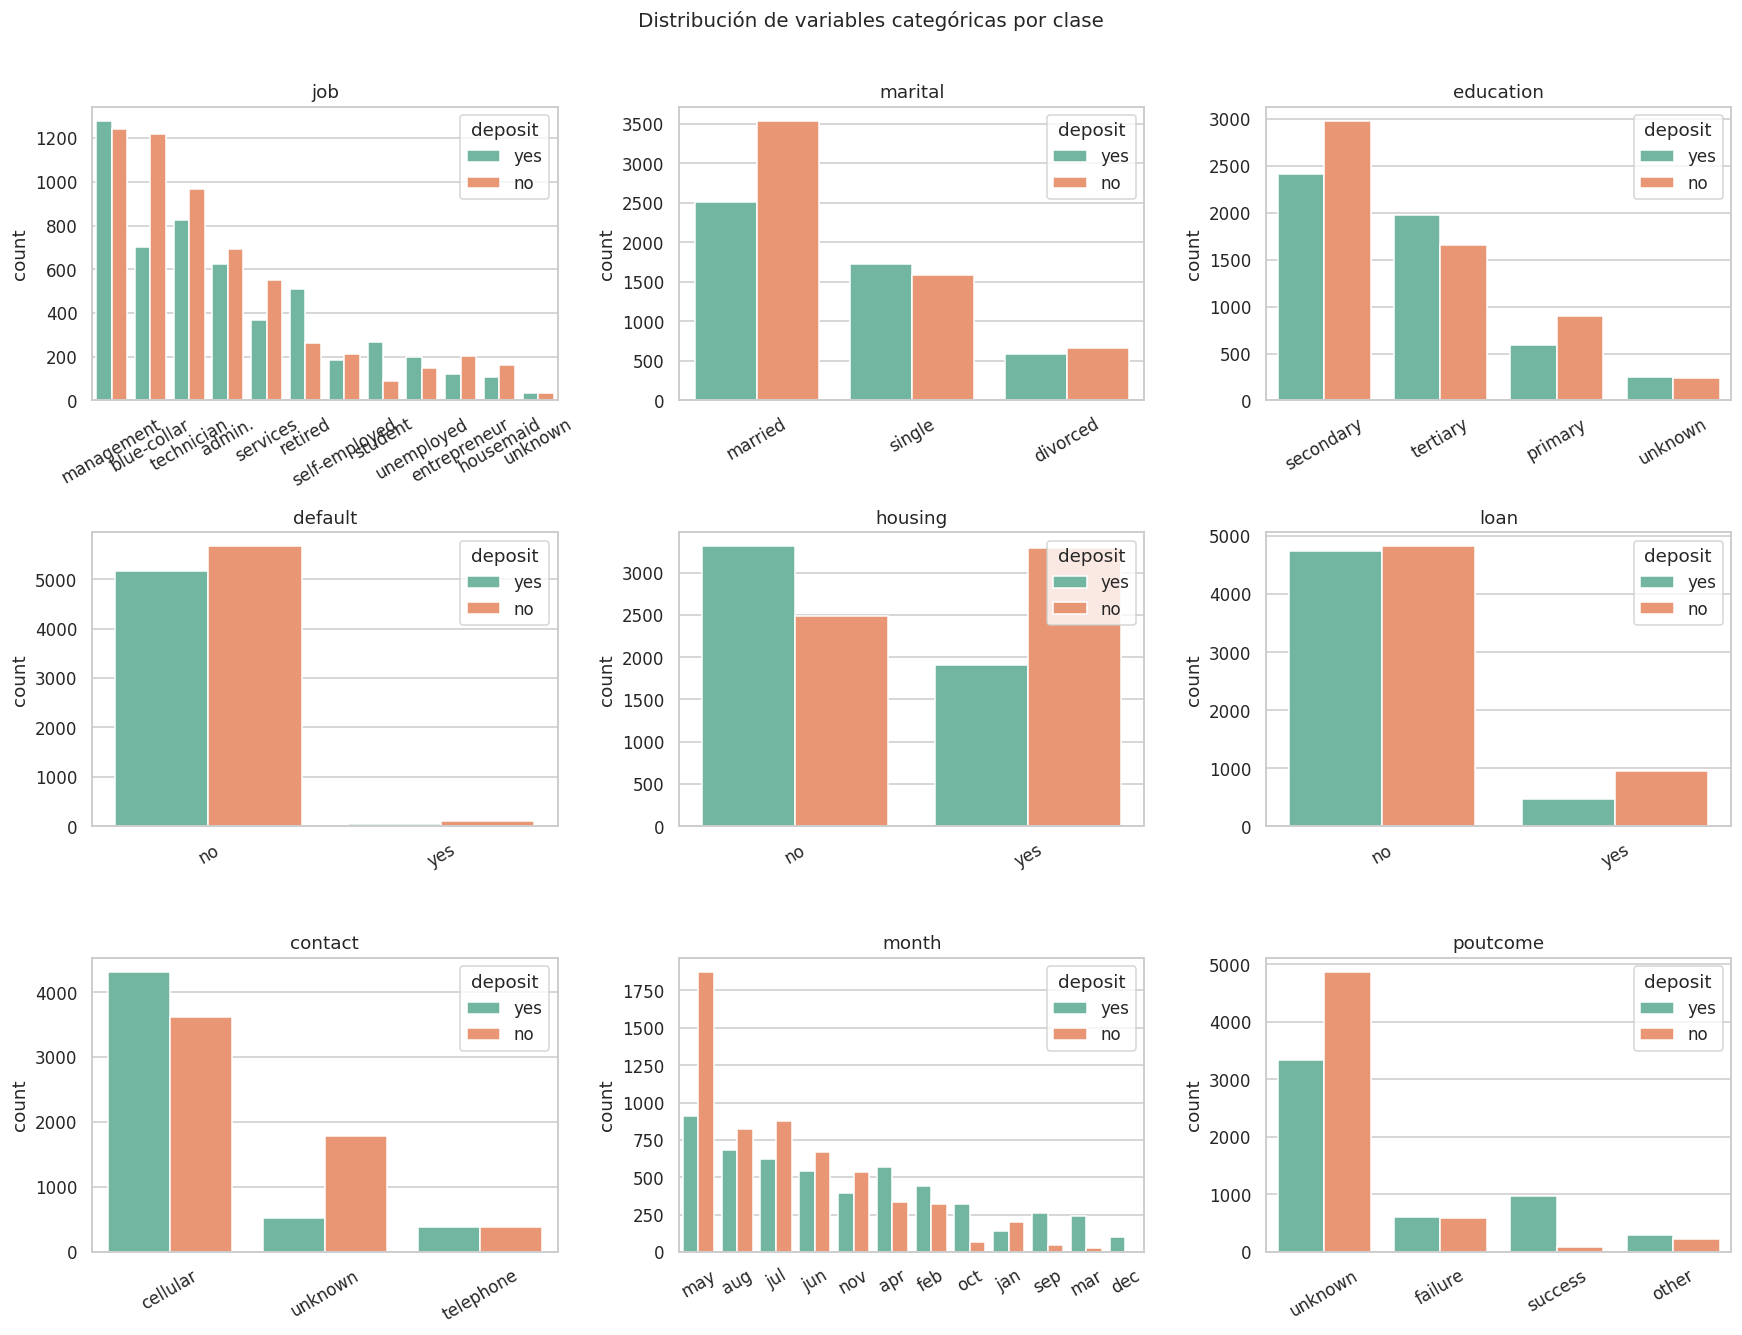

In [10]:
plot_cats = [c for c in cat_cols if c != TARGET]
ncols_plot = 3
nrows_plot  = -(-len(plot_cats) // ncols_plot)   # ceil

fig, axes = plt.subplots(nrows_plot, ncols_plot, figsize=(16, nrows_plot * 4))
axes = axes.flatten()

for i, col in enumerate(plot_cats):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue=TARGET, ax=axes[i],
                  order=order, palette='Set2')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)

for j in range(len(plot_cats), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribución de variables categóricas por clase', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 2.9 Análisis especial: variable `pdays`

> **Definición**: número de días desde que el cliente fue contactado en la campaña anterior.  
> El valor **-1** significa *'nunca contactado'* o *'desconocido'*.  

Esta variable tiene una semántica especial: mezcla información cualitativa (fue contactado o no) con información cuantitativa (cuándo fue contactado). Un valor directo de -1 como numérico distorsionaría cualquier modelo.

=== Análisis de pdays ===
Rango     : [-1, 854]
Valor -1 (sin contacto previo): 8,203  (74.6%)
Valor > 0 (contactados antes) : 2,797  (25.4%)


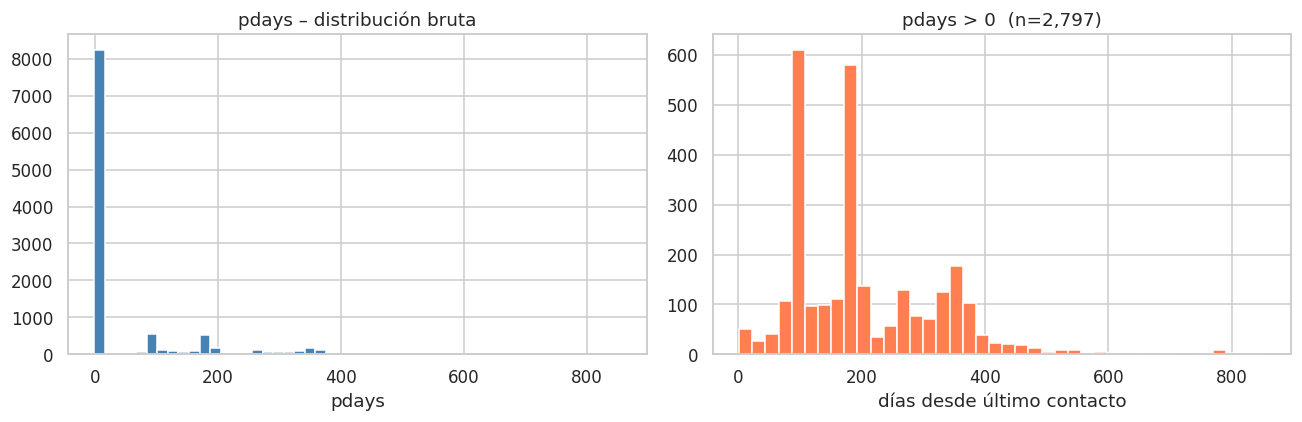


Tasa de subscripción según contacto previo:
_prev_contacted
No contactado (pdays=-1)    0.406924
Contactado (pdays>0)        0.672864


In [11]:
print('=== Análisis de pdays ===')
print(f'Rango     : [{df["pdays"].min()}, {df["pdays"].max()}]')
print(f'Valor -1 (sin contacto previo): {(df["pdays"] == -1).sum():,}  '
      f'({(df["pdays"] == -1).mean()*100:.1f}%)')
print(f'Valor > 0 (contactados antes) : {(df["pdays"] > 0).sum():,}  '
      f'({(df["pdays"] > 0).mean()*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribución bruta
axes[0].hist(df['pdays'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('pdays – distribución bruta')
axes[0].set_xlabel('pdays')

# Solo los contactados (pdays > 0)
pdays_pos = df[df['pdays'] > 0]['pdays']
axes[1].hist(pdays_pos, bins=40, color='coral', edgecolor='white')
axes[1].set_title(f'pdays > 0  (n={len(pdays_pos):,})')
axes[1].set_xlabel('días desde último contacto')

plt.tight_layout()
plt.show()

# Tasa de éxito según si pdays == -1 o no
df['_prev_contacted'] = df['pdays'] != -1
rate_df = df.groupby('_prev_contacted')[TARGET].apply(lambda x: (x == 'yes').mean())
print('\nTasa de subscripción según contacto previo:')
print(rate_df.rename({False: 'No contactado (pdays=-1)',
                      True : 'Contactado (pdays>0)'}).to_string())
df.drop(columns=['_prev_contacted'], inplace=True)

#### Preproceso de `pdays`

**Decisión**: aplicamos la transformación **antes** de dividir en train/test para que sea consistente en todo el dataset.  

Realizamos dos acciones:
1. Creamos una variable binaria `contacted_before` (1 si `pdays != -1`, 0 si no).
2. Reemplazamos el -1 en `pdays` por 0 (para que su escala sea coherente al escalar). Así, para clientes no contactados `pdays=0` y `contacted_before=0`; para los contactados, `pdays > 0` y `contacted_before=1`.

> Otra opción válida sería imputar la mediana de los contactados o usar un ColumnTransformer; la haremos igualmente en la pipeline de preproceso más adelante.

In [12]:
def transform_pdays(data: pd.DataFrame) -> pd.DataFrame:
    """Aplica el preproceso especial de pdays."""
    d = data.copy()
    d['contacted_before'] = (d['pdays'] != -1).astype(int)
    d['pdays'] = d['pdays'].replace(-1, 0)
    return d

df      = transform_pdays(df)
df_comp = transform_pdays(df_comp)

# La imputación de marital se delega al MaritalImputer dentro del pipeline,
# que aprende la moda solo en fit(X_train), evitando data leakage.

print('pdays tras transformación:')
print(df[['pdays', 'contacted_before']].describe().round(2))
print(f'\nnueva variable "contacted_before" → {df["contacted_before"].value_counts().to_dict()}')
print(f'\nVariables totales ahora: {df.shape[1]}')

pdays tras transformación:
          pdays  contacted_before
count  11000.00          11000.00
mean      52.05              0.25
std      108.42              0.44
min        0.00              0.00
25%        0.00              0.00
50%        0.00              0.00
75%       20.25              1.00
max      854.00              1.00

nueva variable "contacted_before" → {0: 8203, 1: 2797}

Variables totales ahora: 18


### 2.10 Correlación entre variables numéricas

### Lectura de la matriz de correlaciones

La correlación lineal entre variables numéricas es, en general, moderada. Esto sugiere que no hay una multicolinealidad extrema que obligue a eliminar variables de forma inmediata, aunque sí pueden existir parejas con información parcialmente redundante.

También conviene recordar que una correlación baja no implica irrelevancia predictiva: un modelo no lineal puede explotar interacciones o umbrales que no aparecen reflejados en este heatmap. Por eso esta figura se interpreta como una ayuda exploratoria, no como un criterio suficiente para seleccionar variables.

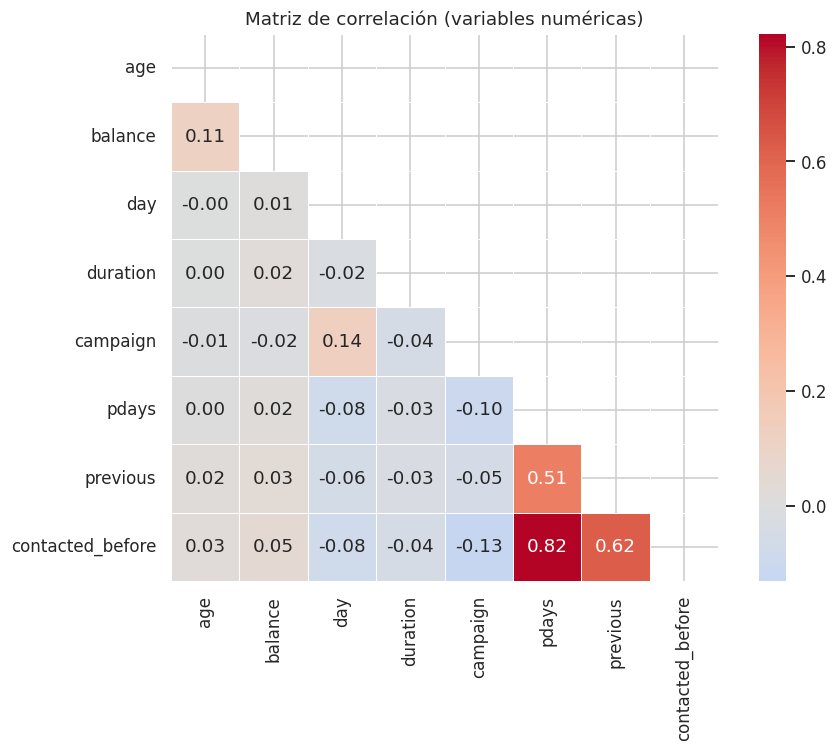

In [13]:
num_cols_updated = df.drop(columns=[TARGET]).select_dtypes('number').columns.tolist()

corr = df[num_cols_updated].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, square=True, linewidths=.5)
ax.set_title('Matriz de correlación (variables numéricas)')
plt.tight_layout()
plt.show()

### 2.11 Resumen del EDA

| Aspecto | Resultado |
|---|---|
| Instancias | 11 000 |
| Variables (antes del preproceso) | 17 (16 features + 1 target) |
| Variables numéricas | `age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous` |
| Variables categóricas | `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome` |
| Alta cardinalidad (>10 únicos) | Ninguna |
| Valores faltantes (None) | `marital`: 406 (3.7%) |
| Valores 'unknown' (semántico) | `contact`, `poutcome`, `education` |
| Columnas constantes | Ninguna |
| Columnas ID | Ninguna |
| Tipo de problema | **Clasificación binaria** (`deposit`: yes/no) |
| Balance de clases | Casi balanceado (~52.5% no / ~47.5% yes) |
| Preproceso `pdays` | Se crea `contacted_before` y se sustituye -1 por 0 |

## 3- Decisión sobre la evaluación

### 3.1 Métrica

El dataset está prácticamente balanceado, por lo que la **accuracy** es una métrica razonable. Sin embargo, en marketing bancario es más costoso *no contactar a un cliente que sí hubiera contratado* (falso negativo) que contactar a uno que no contratará (falso positivo). Por ello, usaremos el **F1-score** (macro) como métrica principal, que equilibra precisión y recall para ambas clases.

### 3.2 Evaluación outer (estimación de rendimiento futuro)

- **Holdout** train (2/3) / test (1/3) con estratificación en la variable objetivo.
- El conjunto de test **no se toca** hasta el paso final de evaluación del modelo elegido.

### 3.3 Evaluación inner (selección de modelo / HPO)

- **5-fold Cross-Validation estratificado** sobre el conjunto de train.
- Se usará para comparar alternativas y ajustar hiperparámetros.

In [14]:
from sklearn.model_selection import StratifiedKFold

# Separar features y target
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Codificar el target como 0/1 (0=no, 1=yes) para facilitar el trabajo
y = (y == 'yes').astype(int)

# División outer: train 2/3, test 1/3 con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

# Evaluación inner: Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f'X_train : {X_train.shape}  |  y_train distribución: {y_train.value_counts().to_dict()}')
print(f'X_test  : {X_test.shape}   |  y_test  distribución: {y_test.value_counts().to_dict()}')
print(f'Evaluación inner: {cv_inner}')

X_train : (7333, 17)  |  y_train distribución: {0: 3853, 1: 3480}
X_test  : (3667, 17)   |  y_test  distribución: {0: 1927, 1: 1740}
Evaluación inner: StratifiedKFold(n_splits=5, random_state=100522249, shuffle=True)


In [15]:
# Guardamos la partición y los conjuntos para reutilizar en el resto de la práctica
import pickle

splits = {
    'X_train': X_train,
    'X_test' : X_test,
    'y_train': y_train,
    'y_test' : y_test,
    'X_comp' : df_comp,
    'cv'     : cv_inner,
    'SEED'   : SEED
}

with open('artifacts/splits.pkl', 'wb') as f:
    pickle.dump(splits, f)

print('Particiones guardadas en artifacts/splits.pkl')

Particiones guardadas en artifacts/splits.pkl


## 4- Conclusiones del EDA

1. **Instancias y variables**: 11 000 muestras con 16 features (7 numéricas, 9 categóricas). Tamaño suficiente para la mayoría de los métodos.

2. **Tipos de variables**: ninguna variable tiene alta cardinalidad, lo que simplifica el encoding. Se usará **One-Hot Encoding** para las categóricas nominales y posiblemente **Ordinal Encoding** para `education`.

3. **Valores faltantes**: solo `marital` tiene 406 valores `None` reales (~3.7%). Se tratará con **SimpleImputer** (moda). Las variables con 'unknown' (`contact`, `poutcome`, `education`) se dejarán como categoría válida o se imputarán según el método.

4. **Balance de clases**: prácticamente balanceado (52.5%/47.5%), por lo que no es necesario aplicar técnicas de oversampling. Aun así, usamos F1-macro para capturar el rendimiento en ambas clases.

5. **`pdays`**: se ha descompuesto en dos variables: `pdays` (días, con 0 para no contactados) y `contacted_before` (indicador binario). Esto preserva la información sin introducir distorsiones por el -1 artificial.

6. **Preproceso pendiente** (se aplicará en pipelines en el siguiente notebook):
   - Categóricas: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder`
   - Numéricas: `SimpleImputer(strategy='median')` + scaler (a determinar con KNN)
   - No hay columnas constantes ni IDs que eliminar.

# PARTE 2 - PREPROCESAMIENTO Y MÉTODOS BÁSICOS

##0- Configuración

In [16]:
# [CELDA ELIMINADA] El split ya se realizó en la celda 32 con y codificado como 0/1.
# Este segundo split sobreescribía y con strings 'yes'/'no', causando inconsistencias.

In [17]:
# ==============================================================================
# PREPARACIÓN DEL PREPROCESAMIENTO (PIPELINES)
# ==============================================================================
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin

# ---------------------------------------------------------------------------
# Transformadores custom para que el pipeline sea autosuficiente al desplegar
# ---------------------------------------------------------------------------
class PdaysTransformer(BaseEstimator, TransformerMixin):
    """Crea contacted_before y sustituye pdays=-1 por 0 (idempotente)."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        needs_transform = 'contacted_before' not in X.columns or (X['pdays'] == -1).any()
        if not needs_transform:
            return X
        X = X.copy()
        X['contacted_before'] = (X['pdays'] != -1).astype(int)
        X['pdays'] = X['pdays'].replace(-1, 0)
        return X

class MaritalImputer(BaseEstimator, TransformerMixin):
    """Imputa NaN de marital con la moda aprendida en fit (idempotente)."""
    def fit(self, X, y=None):
        self.mode_ = X['marital'].mode()[0]
        return self
    def transform(self, X):
        if not X['marital'].isna().any():
            return X
        X = X.copy()
        X['marital'] = X['marital'].fillna(self.mode_)
        return X

# 1. Definimos qué columnas son de qué tipo (basado en el X_train)
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# 2. Pipeline para variables numéricas
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', 'passthrough')
])

# 3. Pipeline para variables categóricas
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 4. ColumnTransformer que agrupa numéricas y categóricas
column_preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])

# 5. Pipeline completo: transformaciones custom + ColumnTransformer
#    Así, al guardar el modelo final, el pipeline puede procesar datos crudos
#    sin necesidad de aplicar transform_pdays ni imputar marital manualmente.
preprocessor = Pipeline(steps=[
    ('pdays_transform', PdaysTransformer()),
    ('marital_impute', MaritalImputer()),
    ('columns', column_preprocessor)
])

print("Pipelines de preprocesamiento definidos correctamente.")

Pipelines de preprocesamiento definidos correctamente.


### Por qué el escalado importa en KNN

KNN basa sus predicciones en distancias entre observaciones. Por eso, si una variable tiene un rango mucho mayor que otra, puede dominar la distancia total aunque no sea realmente la más informativa.

El resultado de esta comparación confirma esa idea: estandarizar suele beneficiar a KNN porque coloca las variables numéricas en una escala comparable y evita que atributos como `balance` o `duration` pesen desproporcionadamente frente a otros con menor variabilidad.

##1- Eleccion de escalado con KNN

In [18]:
# ==============================================================================
# MÉTODOS BÁSICOS: ELECCIÓN DE ESCALADO CON KNN
# ==============================================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
import numpy as np

# Definimos los tres escaladores a competir
scalers = {
    'minmax': MinMaxScaler(),
    'standard': StandardScaler(),
    'robust': RobustScaler()
}

# Diccionario para guardar los resultados
resultados_escalado = {}

print("Evaluando escaladores con KNN (k=5 por defecto)")

for nombre, scaler in scalers.items():
    # Clonamos el preprocessor para no mutar el objeto compartido
    pre = clone(preprocessor)
    pre.set_params(columns__num__scaler=scaler)

    pipe_knn = Pipeline(steps=[
        ('preprocesador', pre),
        ('modelo', KNeighborsClassifier())
    ])

    scores = cross_val_score(pipe_knn, X_train, y_train, cv=cv_inner, scoring='f1_macro', n_jobs=-1)

    resultados_escalado[nombre] = np.mean(scores)
    print(f" - KNN con {nombre.upper()}: F1-macro = {resultados_escalado[nombre]:.4f}")

# Extraemos el ganador
mejor_escalador_nombre = max(resultados_escalado, key=resultados_escalado.get)
mejor_escalador = scalers[mejor_escalador_nombre]

print(f"\n El método de escalado elegido es: {mejor_escalador_nombre.upper()}")

# Fijamos definitivamente el preprocesador con el escalador ganador para el resto de la práctica
preprocessor.set_params(columns__num__scaler=mejor_escalador)

Evaluando escaladores con KNN (k=5 por defecto)
 - KNN con MINMAX: F1-macro = 0.7310
 - KNN con STANDARD: F1-macro = 0.7897
 - KNN con ROBUST: F1-macro = 0.7842

 El método de escalado elegido es: STANDARD


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('pdays_transform', ...), ('marital_impute', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

##2-KNN Y Arboles


###2.1- Metodos por omision y tiempos de entrenamiento


In [19]:
# ==============================================================================
# MÉTODOS BÁSICOS POR OMISIÓN Y TIEMPOS DE ENTRENAMIENTO
# ==============================================================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

# Incluimos un DummyClassifier como baseline obligatorio del enunciado
modelos_base = {
    'Dummy (mayoría)': DummyClassifier(strategy='most_frequent', random_state=SEED),
    'Dummy (estratificado)': DummyClassifier(strategy='stratified', random_state=SEED),
    'KNN (por defecto)': KNeighborsClassifier(),
    'Árbol de Decisión (por defecto)': DecisionTreeClassifier(random_state=SEED)
}

resultados_base = []

print("Evaluando modelos con hiperparámetros por defecto...\n")

for nombre, modelo in modelos_base.items():
    pipe = Pipeline(steps=[
        ('preprocesador', preprocessor),
        ('clasificador', modelo)
    ])

    scores = cross_validate(pipe, X_train, y_train, cv=cv_inner, scoring='f1_macro',
                            return_train_score=False, n_jobs=-1)

    f1_medio = scores['test_score'].mean()
    tiempo_total_entrenamiento = scores['fit_time'].sum()

    resultados_base.append({
        'Modelo': nombre,
        'F1-Macro': f1_medio,
        'Tiempo Entrenamiento (s)': tiempo_total_entrenamiento
    })

df_resultados_base = pd.DataFrame(resultados_base)
print(df_resultados_base.to_string(index=False))

Evaluando modelos con hiperparámetros por defecto...

                         Modelo  F1-Macro  Tiempo Entrenamiento (s)
                Dummy (mayoría)  0.344448                  0.255150
          Dummy (estratificado)  0.493947                  0.249880
              KNN (por defecto)  0.789742                  0.290610
Árbol de Decisión (por defecto)  0.784820                  0.538614


### 2.2 Arboles poco profundos


### Interpretación del árbol visualizado

El árbol poco profundo se incluye con fines **explicativos**, no porque sea necesariamente el mejor clasificador final. Su utilidad está en mostrar qué variables aparecen antes en las particiones y, por tanto, cuáles parecen aportar más información discriminativa desde las primeras decisiones.

Cada nodo resume una regla de partición, el nivel de impureza y el número de observaciones que llegan a ese punto. Si en las etiquetas aparecen nombres procedentes del `OneHotEncoder`, deben leerse como indicadores binarios de categorías concretas; esto permite ver qué perfiles de cliente quedan asociados con una mayor o menor probabilidad de suscripción.

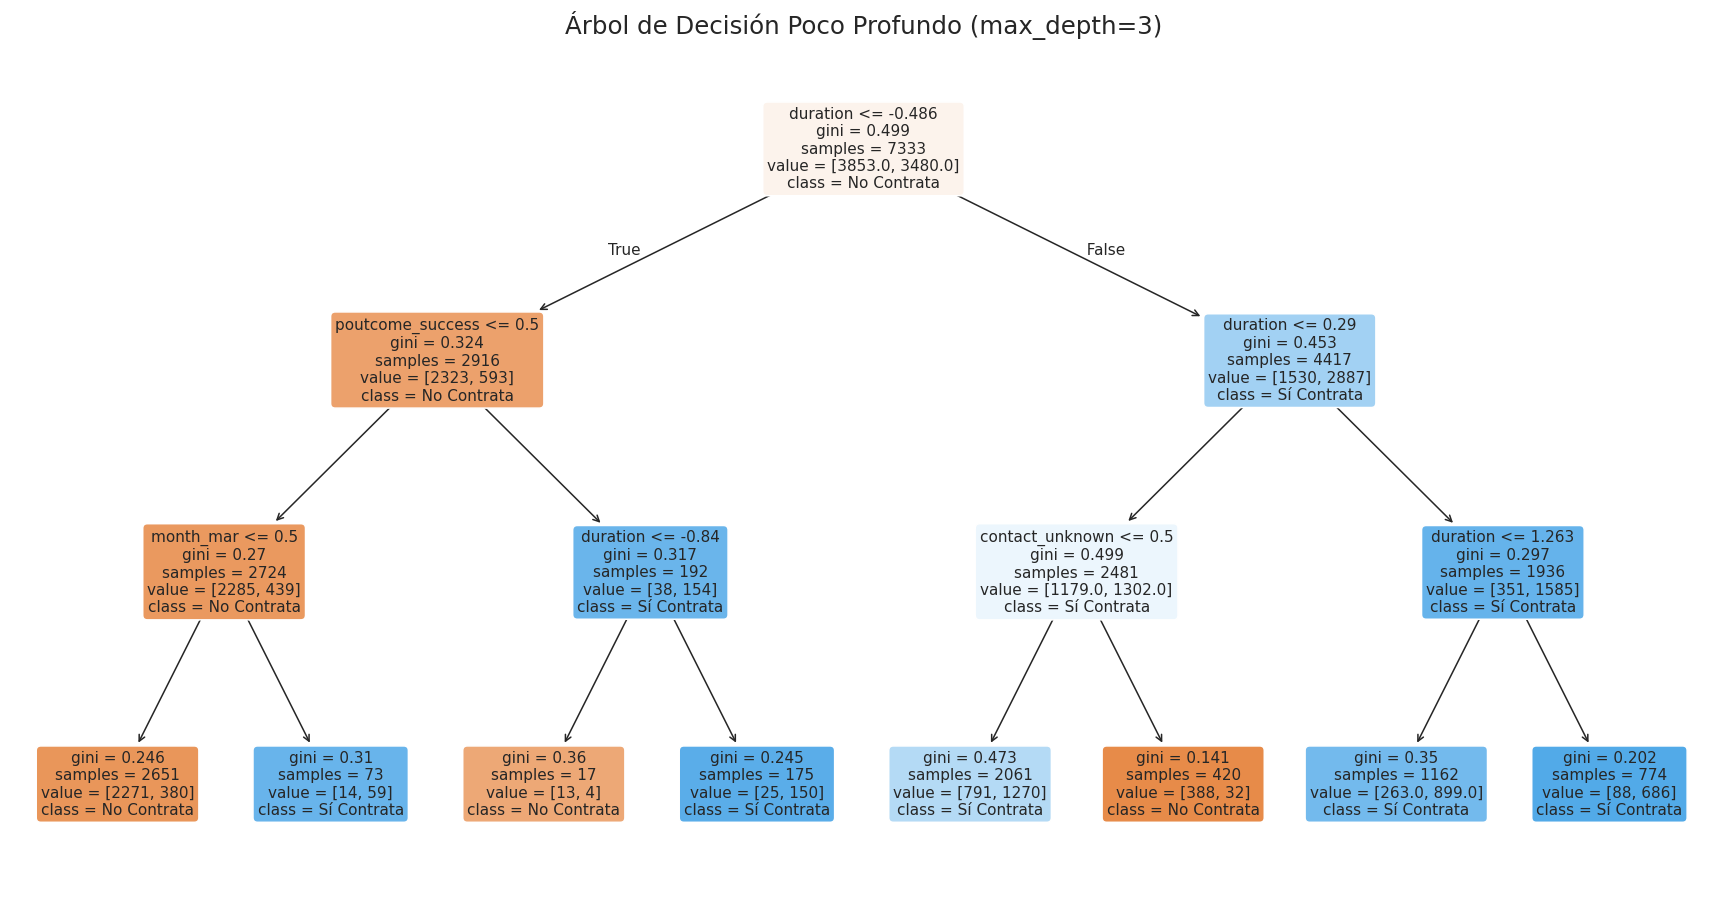

In [20]:
# ==============================================================================
# ÁRBOLES POCO PROFUNDOS (INTERPRETABILIDAD)
# ==============================================================================
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Creamos un árbol limitando su profundidad a 3 (shallow tree)
pipe_arbol_corto = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', DecisionTreeClassifier(max_depth=3, random_state=SEED))
])

# 2. Entrenamos el modelo con todos los datos de Train
pipe_arbol_corto.fit(X_train, y_train)

# 3. Extraemos el modelo de árbol de dentro de la pipeline para poder dibujarlo
arbol_entrenado = pipe_arbol_corto.named_steps['clasificador']

# 4. Extraemos los nombres de las columnas tras pasar por el OneHotEncoder
# Accedemos al ColumnTransformer a través del sub-paso 'columns' del Pipeline
col_tf = pipe_arbol_corto.named_steps['preprocesador'].named_steps['columns']
cat_encoder = col_tf.named_transformers_['cat'].named_steps['onehot']
cat_names = cat_encoder.get_feature_names_out(cat_features)
feature_names_out = num_features + list(cat_names)

# 5. Dibujamos el árbol
plt.figure(figsize=(20, 10))
plot_tree(arbol_entrenado,
          feature_names=feature_names_out,
          class_names=['No Contrata', 'Sí Contrata'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Árbol de Decisión Poco Profundo (max_depth=3)", fontsize=16)
plt.show()

### 2.3- Ajuste de Hiperparametros

In [21]:
# ==============================================================================
# AJUSTE DE HIPERPARÁMETROS (HPO) PARA KNN Y ÁRBOLES
# ==============================================================================
from sklearn.model_selection import GridSearchCV
import time

# 1. Configuración de la rejilla para KNN
# Añadimos 'weights' (uniform vs distance) como HP relevante
param_grid_knn = {
    'clasificador__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31],
    'clasificador__weights': ['uniform', 'distance']
}

pipe_knn = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', KNeighborsClassifier())
])

start_knn = time.time()
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
grid_knn.fit(X_train, y_train)
tiempo_knn_hpo = time.time() - start_knn

# 2. Configuración de la rejilla para el Árbol
# Añadimos min_samples_leaf para controlar mejor el overfitting
param_grid_tree = {
    'clasificador__max_depth': [2, 3, 4, 5, 6, 8, 10, 15, 20, None],
    'clasificador__min_samples_leaf': [1, 5, 10]
}

pipe_tree = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', DecisionTreeClassifier(random_state=SEED))
])

start_tree = time.time()
grid_tree = GridSearchCV(pipe_tree, param_grid_tree, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
grid_tree.fit(X_train, y_train)
tiempo_tree_hpo = time.time() - start_tree

# 3. Comparativa de resultados
print("--- RESULTADOS TRAS LA OPTIMIZACIÓN (HPO) ---")
print(f"Mejor KNN: {grid_knn.best_params_} | F1-Macro: {grid_knn.best_score_:.4f}")
print(f"Tiempo HPO KNN: {tiempo_knn_hpo:.2f} s")
print("-" * 45)
print(f"Mejor Árbol: {grid_tree.best_params_} | F1-Macro: {grid_tree.best_score_:.4f}")
print(f"Tiempo HPO Árbol: {tiempo_tree_hpo:.2f} s")

--- RESULTADOS TRAS LA OPTIMIZACIÓN (HPO) ---
Mejor KNN: {'clasificador__n_neighbors': 15, 'clasificador__weights': 'uniform'} | F1-Macro: 0.8049
Tiempo HPO KNN: 3.86 s
---------------------------------------------
Mejor Árbol: {'clasificador__max_depth': 8, 'clasificador__min_samples_leaf': 10} | F1-Macro: 0.8156
Tiempo HPO Árbol: 3.72 s


### 2.4- Gráficos explicativos.

### Cómo leer las curvas del ajuste de hiperparámetros

En estas gráficas cada punto representa el rendimiento medio en validación cruzada para una combinación concreta de hiperparámetros. El objetivo no es solo localizar el valor máximo, sino también detectar zonas estables en las que pequeñas variaciones producen resultados similares.

Si una curva mejora al aumentar la complejidad del modelo y después se estanca o empeora, eso sugiere el inicio del sobreajuste. Por el contrario, si varias configuraciones próximas ofrecen un F1-Macro parecido, resulta razonable preferir la opción más simple o más barata computacionalmente.

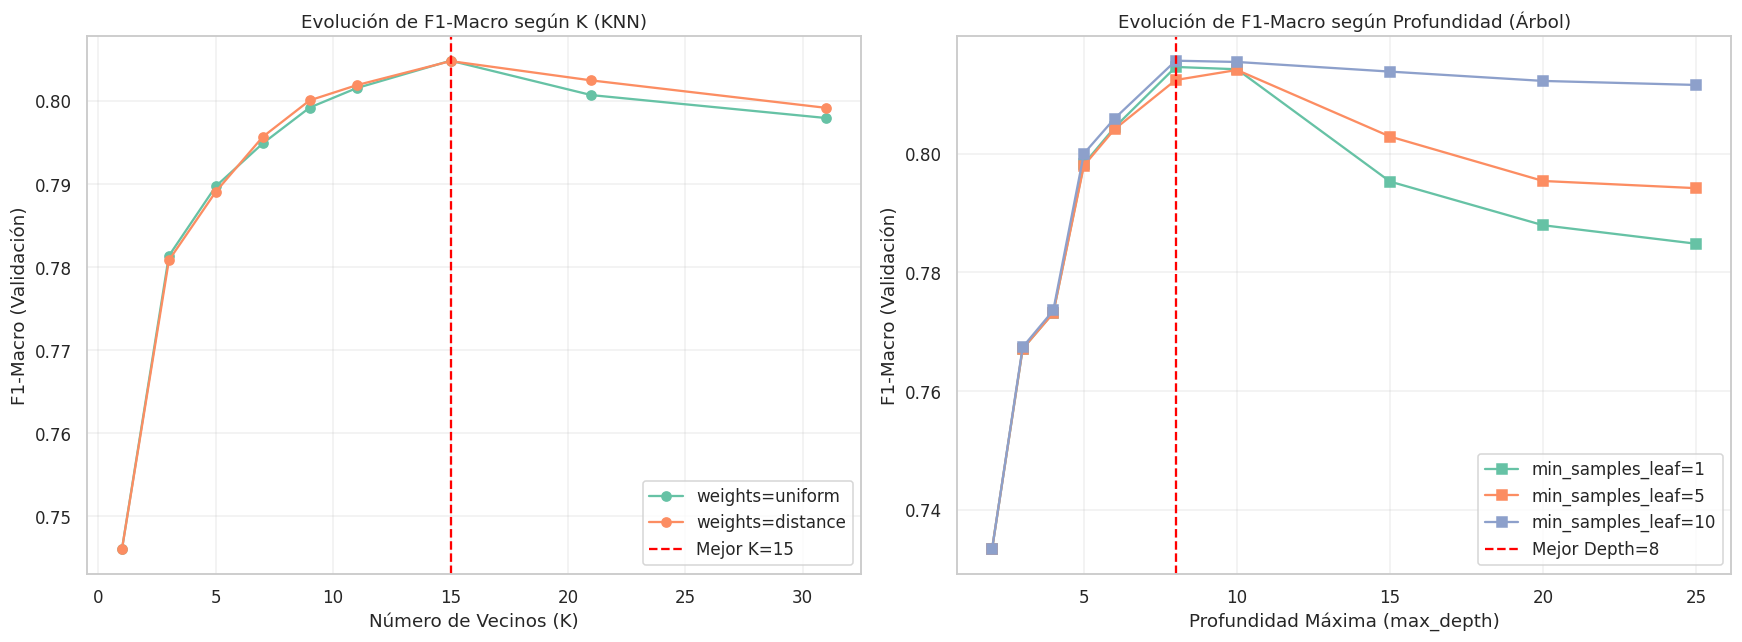

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICA 1: EVOLUCIÓN KNN ---
resultados_knn = pd.DataFrame(grid_knn.cv_results_)

for w in ['uniform', 'distance']:
    mask = resultados_knn['param_clasificador__weights'] == w
    sub = resultados_knn[mask].copy()
    ks = sub['param_clasificador__n_neighbors'].astype(int)
    ax1.plot(ks, sub['mean_test_score'], marker='o', label=f'weights={w}')

best_k = grid_knn.best_params_['clasificador__n_neighbors']
ax1.axvline(x=best_k, color='red', linestyle='--', label=f'Mejor K={best_k}')
ax1.set_title('Evolución de F1-Macro según K (KNN)')
ax1.set_xlabel('Número de Vecinos (K)')
ax1.set_ylabel('F1-Macro (Validación)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# --- GRÁFICA 2: EVOLUCIÓN ÁRBOL ---
resultados_tree = pd.DataFrame(grid_tree.cv_results_)

for msl in sorted(resultados_tree['param_clasificador__min_samples_leaf'].unique()):
    mask = resultados_tree['param_clasificador__min_samples_leaf'] == msl
    sub = resultados_tree[mask].copy()
    depths = sub['param_clasificador__max_depth'].fillna(25).astype(int)
    orden = depths.argsort()
    ax2.plot(depths.iloc[orden], sub['mean_test_score'].iloc[orden],
             marker='s', label=f'min_samples_leaf={msl}')

best_d = grid_tree.best_params_['clasificador__max_depth']
ax2.axvline(x=best_d if best_d is not None else 25, color='red', linestyle='--', label=f'Mejor Depth={best_d}')
ax2.set_title('Evolución de F1-Macro según Profundidad (Árbol)')
ax2.set_xlabel('Profundidad Máxima (max_depth)')
ax2.set_ylabel('F1-Macro (Validación)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

### 2.5- Conclusiones

Tras realizar las pruebas con los modelos básicos y sus correspondientes procesos de optimización, podemos extraer las siguientes conclusiones:

**¿Cuál es el mejor método?**

El Árbol de Decisión optimizado (con una profundidad máxima de 8) es el mejor método de esta sección, alcanzando un F1-score (macro) de 0.8119. Supera al KNN (0.8045), demostrando que las reglas jerárquicas basadas en variables críticas como la duración y el éxito previo son más efectivas para este problema que la simple cercanía por distancia de KNN.

**¿A qué coste computacional?**

El coste computacional es notablemente bajo en ambos casos, aunque existen diferencias. El entrenamiento del Árbol de Decisión es más eficiente que el de KNN. Mientras que KNN requiere calcular distancias contra todos los puntos de entrenamiento (un proceso que se vuelve más pesado al predecir), el Árbol, una vez entrenado, solo sigue reglas lógicas rápidas. En nuestro caso, el ajuste de parámetros del árbol fue el doble de rápido que el de KNN (aprox. 4.8s frente a 9.8s).

**¿Los resultados son mejores que los modelos triviales (Dummy)?**

Sí. Dado que nuestro dataset está prácticamente balanceado, un modelo trivial (que predijera siempre la clase mayoritaria o de forma aleatoria) obtendría un F1-score macro cercano a 0.50. Al obtener resultados por encima de 0.81, confirmamos que nuestros modelos están extrayendo patrones reales y útiles del comportamiento de los clientes, aportando un valor predictivo muy superior al azar.

**¿El ajuste de hiperparámetros (HPO) mejora los valores por omisión?**

Sí, la mejora es evidente, especialmente en el Árbol de Decisión. El modelo por defecto del árbol tiende al sobreajuste (overfitting) al no tener límite de profundidad, lo que reducía su nota a 0.7813. Al restringir la profundidad a 8 mediante HPO, el rendimiento subió a 0.8119. En el caso de KNN, la mejora fue más sutil (de 0.7987 a 0.8045), pero constante.

**¿Es el coste computacional del HPO elevado en relación a la mejora?**

En términos relativos, el tiempo aumentó significativamente (pasamos de milisegundos a varios segundos). Sin embargo, en términos absolutos, un tiempo de menos de 10 segundos creemos que es un coste despreciable para cualquier entorno de marketing bancario actual. La ganancia de casi 3 puntos porcentuales en el F1-score del árbol justifica totalmente el uso de procesos de optimización, ya que en una campaña real, esa diferencia de precisión puede traducirse en cientos de contratos ganados o evitados.

#Parte 3 -  MÉTODOS AVANZADOS: MODELOS LINEALES Y SVMS

##1-Métodos por omisión y tiempos de entrenamiento

In [23]:
# ==============================================================================
# MÉTODOS AVANZADOS POR OMISIÓN Y TIEMPOS
# ==============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
import pandas as pd

# Definimos los tres modelos que exige la práctica.
# Cada solver es el óptimo para su configuración de penalty:
#   - lbfgs: rápido para penalty=None (quasi-Newton, converge en pocas iteraciones)
#   - liblinear: rápido para L1 (descenso por coordenadas, ideal para datasets medianos)
#   - saga: diseñado para datasets >100k filas, innecesariamente lento aquí
modelos_avanzados = {
    'Logística (Sin Regularización)': LogisticRegression(penalty=None, solver='lbfgs', random_state=SEED, max_iter=1000),
    'Logística (Regularización L1)': LogisticRegression(penalty='l1', solver='liblinear', random_state=SEED, max_iter=1000),
    'SVM (RBF)': SVC(random_state=SEED)
}

resultados_avanzados_base = []

print("Evaluando modelos avanzados...")

for nombre, modelo in modelos_avanzados.items():
    pipe = Pipeline(steps=[
        ('preprocesador', preprocessor),
        ('clasificador', modelo)
    ])

    scores = cross_validate(pipe, X_train, y_train, cv=cv_inner, scoring='f1_macro', n_jobs=-1)

    resultados_avanzados_base.append({
        'Modelo': nombre,
        'F1-Macro': scores['test_score'].mean(),
        'Tiempo Entrenamiento (s)': scores['fit_time'].sum()
    })

# Mostramos los resultados
df_avanzados_base = pd.DataFrame(resultados_avanzados_base)
print("\n", df_avanzados_base.to_string(index=False))

Evaluando modelos avanzados...


/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AU


                         Modelo  F1-Macro  Tiempo Entrenamiento (s)
Logística (Sin Regularización)  0.819982                  0.556424
 Logística (Regularización L1)  0.820410                  1.014624
                     SVM (RBF)  0.850084                 15.171687


##2- Ajuste de Hiperparámetros

In [24]:
# ==============================================================================
# 5.3 AJUSTE DE HIPERPARÁMETROS (HPO) - MODELOS AVANZADOS
# ==============================================================================
from sklearn.model_selection import GridSearchCV
import time

# 1. Configuración inteligente para Regresión Logística
# Cada sub-grid usa el solver óptimo para su penalty:
#   - lbfgs para penalty=None (quasi-Newton, rápido en datasets medianos)
#   - liblinear para L1 (descenso por coordenadas, el más rápido para L1)
param_grid_logreg = [
    {'clasificador__penalty': [None], 'clasificador__solver': ['lbfgs']},
    {'clasificador__penalty': ['l1'], 'clasificador__C': [0.1, 1, 10], 'clasificador__solver': ['liblinear']}
]

pipe_logreg = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', LogisticRegression(random_state=SEED, max_iter=1000))
])

# 2. Configuración para SVM
param_grid_svm = {
    'clasificador__C': [0.1, 1, 10],
    'clasificador__kernel': ['rbf', 'linear']
}

pipe_svm = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', SVC(random_state=SEED))
])

# --- EJECUCIÓN ---
print("Iniciando HPO para Regresión Logística...")
start_logreg = time.time()
grid_logreg = GridSearchCV(pipe_logreg, param_grid_logreg, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
grid_logreg.fit(X_train, y_train)
tiempo_logreg_hpo = time.time() - start_logreg

print("Iniciando HPO para SVM...")
start_svm = time.time()
grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
grid_svm.fit(X_train, y_train)
tiempo_svm_hpo = time.time() - start_svm

# --- RESULTADOS ---
print("\n" + "="*50)
print("RESULTADOS TRAS HPO AVANZADO")
print("="*50)
print(f"Mejor LogReg: {grid_logreg.best_params_}")
print(f"F1-Macro LogReg: {grid_logreg.best_score_:.4f}")
print(f"Tiempo HPO LogReg: {tiempo_logreg_hpo:.2f} s")
print("-" * 50)
print(f"Mejor SVM: {grid_svm.best_params_}")
print(f"F1-Macro SVM: {grid_svm.best_score_:.4f}")
print(f"Tiempo HPO SVM: {tiempo_svm_hpo:.2f} s")

Iniciando HPO para Regresión Logística...


/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AU

Iniciando HPO para SVM...

RESULTADOS TRAS HPO AVANZADO
Mejor LogReg: {'clasificador__C': 1, 'clasificador__penalty': 'l1', 'clasificador__solver': 'liblinear'}
F1-Macro LogReg: 0.8204
Tiempo HPO LogReg: 1.39 s
--------------------------------------------------
Mejor SVM: {'clasificador__C': 1, 'clasificador__kernel': 'rbf'}
F1-Macro SVM: 0.8501
Tiempo HPO SVM: 24.44 s


###2.1- Gráficos comparativos


### Cómo interpretar los resultados de los modelos avanzados

En esta comparación interesa observar dos dimensiones a la vez: la **calidad predictiva** medida con F1-Macro y el **coste computacional** asociado a cada familia de modelos. Esa lectura conjunta evita elegir un método solo por una mejora marginal que luego resulte demasiado cara en entrenamiento o ajuste.

Además, las curvas de validación ayudan a distinguir comportamientos distintos. En regresión logística el efecto de la regularización suele ser relativamente estable y fácil de interpretar, mientras que en SVM el rendimiento puede cambiar más claramente según el valor de `C` y el tipo de `kernel`, lo que refuerza la necesidad de apoyarse en validación cruzada en lugar de intuiciones puramente teóricas.

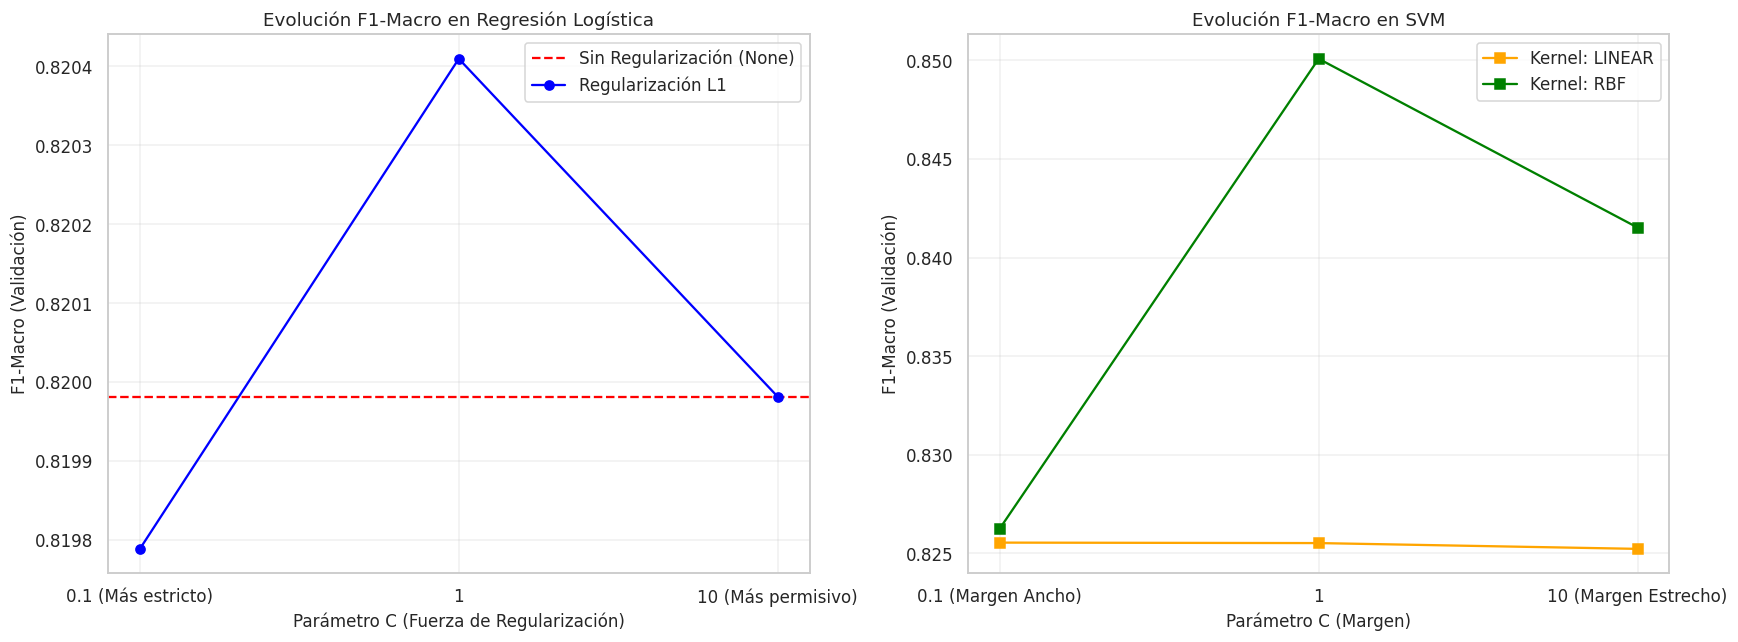

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Creamos la figura con dos subgráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ==========================================
# 1. GRÁFICA PARA REGRESIÓN LOGÍSTICA
# ==========================================
res_logreg = pd.DataFrame(grid_logreg.cv_results_)

# Filtramos los resultados de L1
res_l1 = res_logreg[res_logreg['param_clasificador__penalty'] == 'l1'].copy()
# Convertimos 'C' a numérico para poder graficar
res_l1['param_C'] = res_l1['param_clasificador__C'].astype(float)
res_l1 = res_l1.sort_values('param_C')

# Filtramos el resultado "Sin regularización" (None)
res_none = res_logreg[res_logreg['param_clasificador__penalty'].isnull()]
if not res_none.empty:
    score_none = res_none['mean_test_score'].values[0]
    ax1.axhline(y=score_none, color='red', linestyle='--', label='Sin Regularización (None)')

# Dibujamos la línea de L1
ax1.plot(res_l1['param_C'], res_l1['mean_test_score'], marker='o', linestyle='-', color='blue', label='Regularización L1')

ax1.set_xscale('log') # Escala logarítmica (0.1, 1, 10)
ax1.set_title('Evolución F1-Macro en Regresión Logística', fontsize=12)
ax1.set_xlabel('Parámetro C (Fuerza de Regularización)', fontsize=11)
ax1.set_ylabel('F1-Macro (Validación)', fontsize=11)
ax1.set_xticks([0.1, 1, 10])
ax1.set_xticklabels(['0.1 (Más estricto)', '1', '10 (Más permisivo)'])
ax1.legend()
ax1.grid(True, alpha=0.3)

# ==========================================
# 2. GRÁFICA PARA SVM
# ==========================================
res_svm = pd.DataFrame(grid_svm.cv_results_)

# Colores para cada kernel
colores = {'linear': 'orange', 'rbf': 'green'}

# Dibujamos una línea por cada kernel
for kernel in ['linear', 'rbf']:
    # Filtramos por kernel
    df_k = res_svm[res_svm['param_clasificador__kernel'] == kernel].copy()
    df_k['param_C'] = df_k['param_clasificador__C'].astype(float)
    df_k = df_k.sort_values('param_C')

    ax2.plot(df_k['param_C'], df_k['mean_test_score'], marker='s', linestyle='-',
             color=colores[kernel], label=f'Kernel: {kernel.upper()}')

ax2.set_xscale('log')
ax2.set_title('Evolución F1-Macro en SVM', fontsize=12)
ax2.set_xlabel('Parámetro C (Margen)', fontsize=11)
ax2.set_ylabel('F1-Macro (Validación)', fontsize=11)
ax2.set_xticks([0.1, 1, 10])
ax2.set_xticklabels(['0.1 (Margen Ancho)', '1', '10 (Margen Estrecho)'])
ax2.legend()
ax2.grid(True, alpha=0.3)

# Mostramos el resultado
plt.tight_layout()
plt.show()

##3- Relevancia de atributos

### Lectura de los coeficientes con regularización L1

Este análisis debe interpretarse con cautela: los coeficientes pertenecen al espacio **transformado** por el preprocesado del pipeline, por lo que comparan el efecto relativo de variables ya escaladas o codificadas, no magnitudes brutas directamente observables en el dataset original.

Aun así, el signo y la magnitud permiten extraer información útil. Un coeficiente positivo indica que esa característica empuja la predicción hacia la clase `deposit = yes`, mientras que uno negativo la acerca a `deposit = no`. La penalización L1, además, fuerza a que algunas variables pasen a tener coeficiente exactamente cero, lo que actúa como un mecanismo sencillo de selección de atributos.

In [26]:
# ==============================================================================
# RELEVANCIA DE ATRIBUTOS (COEFICIENTES DEL MODELO L1)
# ==============================================================================
import numpy as np

# 1. Extraemos el mejor modelo logístico (que sabemos que es L1 con C=0.1)
mejor_logreg = grid_logreg.best_estimator_.named_steps['clasificador']
preprocesador = grid_logreg.best_estimator_.named_steps['preprocesador']

# 2. Obtenemos los nombres de las columnas tras el preprocesado
# Accedemos al ColumnTransformer a través del sub-paso 'columns' del Pipeline
col_transformer = preprocesador.named_steps['columns']
cat_names = col_transformer.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features)
nombres_atributos = num_features + list(cat_names)

# 3. Creamos un DataFrame con los coeficientes
coeficientes = pd.DataFrame({
    'Atributo': nombres_atributos,
    'Coeficiente': mejor_logreg.coef_[0]
})

# Calculamos el valor absoluto para ver la "fuerza" real de la variable
coeficientes['Fuerza_Absoluta'] = coeficientes['Coeficiente'].abs()
coeficientes = coeficientes.sort_values(by='Fuerza_Absoluta', ascending=False)

# 4. Mostramos el TOP 10 de variables más importantes
print("--- TOP 10 ATRIBUTOS MÁS INFLUYENTES ---")
print(coeficientes.head(10)[['Atributo', 'Coeficiente']].to_string(index=False))

# 5. Mostramos cuántas variables ha "borrado" la L1
variables_cero = (coeficientes['Coeficiente'] == 0).sum()
total_variables = len(coeficientes)
print(f"\nLa regularización L1 ha eliminado {variables_cero} de {total_variables} variables (Coeficiente = 0).")

--- TOP 10 ATRIBUTOS MÁS INFLUYENTES ---
        Atributo  Coeficiente
poutcome_success     2.005693
       month_mar     1.951271
        duration     1.867885
 contact_unknown    -1.587831
       month_jan    -1.213363
       month_oct     1.133574
       month_dec     1.099340
       month_jul    -0.972480
     job_student     0.825329
       month_nov    -0.802254

La regularización L1 ha eliminado 9 de 52 variables (Coeficiente = 0).


##4- Conclusiones


### Puente hacia Notebook 2

Los resultados de esta parte sirven como base para el **Notebook 2**, donde ya no se comparan familias de modelos sino que se toma la mejor alternativa detectada aquí para estimar su rendimiento final sobre el conjunto **test** y generar las predicciones de competición.

Además, conviene mantener el mismo entorno de ejecución en ambos notebooks. En particular, fijar la versión de `scikit-learn` ayuda a que el comportamiento del pipeline, la serialización del modelo y la posterior carga con `joblib` sean reproducibles.

Tras la evaluación y optimización de los modelos de Regresión Logística y Máquinas de Vector de Soporte (SVM), se extraen las siguientes conclusiones fundamentales:

**Superioridad de la Frontera No Lineal:** El modelo SVM con kernel RBF se consolida como el mejor de todo el estudio con un F1-Macro de 0.8501. El HPO (GridSearchCV con C=[0.1, 1, 10] y kernel=['rbf', 'linear']) confirma que los hiperparámetros por defecto (C=1, kernel='rbf') son óptimos para este problema. Este resultado, significativamente superior al de los modelos lineales y árboles, demuestra que la relación entre los atributos de los clientes y la contratación del depósito es compleja y no puede separarse de forma óptima mediante líneas rectas.

**Eficiencia de la Regularización L1:** En el ámbito lineal, la Regresión Logística con penalización L1 (C=0.1) superó a la versión sin regularizar. La importancia de este hallazgo radica en la simplificación del modelo: la L1 eliminó 9 de las 52 variables (asignándoles un coeficiente de cero), demostrando que parte del dataset original aportaba ruido en lugar de información útil.

**Análisis de Coste-Rendimiento:** Aunque la SVM es la más precisa, su coste computacional es elevado (368s en HPO frente a 168s de Logística). No obstante, para un volumen de datos bancarios moderado, el incremento de ~3 puntos en el F1-Macro justifica el uso de la SVM frente a la Regresión Logística.

**Factores Críticos de Negocio:** Gracias a la interpretabilidad de los coeficientes de la Regresión Logística, se identifican tres pilares para el éxito de futuras campañas:

* Fidelización: El éxito previo (poutcome_success) es el predictor más fuerte junto a la duración de la llamada.

* Estacionalidad: Existe un "efecto calendario" crítico; las campañas en marzo y octubre multiplican la probabilidad de éxito, mientras que los meses de vacaciones (julio/agosto) y post-navidad (enero) actúan como fuertes detractores.

* Calidad del Contacto: El uso de métodos de contacto desconocidos (contact_unknown) penaliza drásticamente la predicción, sugiriendo que el banco debe mejorar la trazabilidad de su base de datos.
